# Interaktionen und Shapley-Unsicherheitskarten

### Welche Merkmale *und welche Kombinationen von Merkmalen* machen ein Modell unsicher, und ist es Rauschen oder fehlendes Wissen?

**Projekt shapiq-probly** · Einarbeitung für das Team · Stand 09.11.2026

---

**Worum es geht:** Dieses Notebook erklärt Schritt für Schritt zwei Bausteine, die für unser Projekt zentral sein könnten:

1. **Shapley-Interaktionen**: Wie man nicht nur einzelne Merkmale, sondern *Merkmalspaare* als Ursache von Unsicherheit erkennt.
2. **Shapley-Unsicherheitskarten**: Wie man diese Erklärungen über den ganzen Merkmalsraum hinweg sichtbar macht.

Am Ende steht, **warum das für den Verlauf unseres Projekts relevant ist**: welche Kurserwartungen es abdeckt, welche Designfragen (D1–D6) es berührt und wie daraus Code in `src/` werden kann.

**Technisches:**
- Läuft mit `numpy`, `scikit-learn`, `matplotlib`, `pandas`. **shapiq und probly werden hier noch nicht benötigt.** Alle Shapley-Größen werden *exakt und von Hand* berechnet, damit jede Formel sichtbar bleibt. Der Anhang zeigt, wie das später auf `shapiq.Game` und probly abgebildet wird.
- Als Präsentation nutzbar: Die Zellen haben Folien-Metadaten. Mit [RISE](https://rise.readthedocs.io/) oder `jupyter nbconvert --to slides notebook.ipynb --post serve` wird daraus eine Foliendarstellung.
- Laufzeit „Restart & Run All“: unter einer Minute.

## Agenda

| # | Abschnitt | Frage, die er beantwortet |
|---|---|---|
| 1 | Motivation | Warum reichen einzelne Shapley-Werte nicht? |
| 2 | Shapley-Werte in 5 Minuten | Was ist ein Spiel, was ist ein Shapley-Wert? |
| 3 | Interaktionen | Was verschmieren Shapley-Werte, und wie holt man es zurück? |
| 4 | Unsicherheit zerlegen | Was sind TU, AU und EU? |
| 5 | TwoMoons und ein Ensemble | Wo ist unser Modell unsicher? |
| 6 | Das Unsicherheitsspiel | Wie wird Unsicherheit zu einem shapiq-Spiel? |
| 7 | Einzelne Punkte erklären | Wie sieht eine Erklärung aus? |
| 8 | **Shapley-Unsicherheitskarten** | Wo im Merkmalsraum treibt welches Merkmal (welche Kombination) die Unsicherheit? |
| 9 | Designfrage D1 | Erst mitteln, dann messen, oder umgekehrt? |
| 10 | Designfrage D2 | Erzeugt die Erklärmethode ihre eigene Unsicherheit? |
| 11 | Benchmark mit Ground Truth (N1) | Finden wir eingebaute Effekte wieder? |
| 12 | Vor- und Nachteile | Was spricht dafür, was dagegen? |
| 13 | **Relevanz für unser Projekt** | Wie geht es weiter? |
| A | Anhang | Brücke zu shapiq und probly |

### Setup

Imports, feste Seeds und ein einheitlicher Plot-Stil. Die Farben haben **feste Bedeutungen** im ganzen Notebook:

- <span style="color:#1baf7a">■</span> **TU** (totale Unsicherheit) · <span style="color:#eb6834">■</span> **AU** (aleatorisch, Rauschen) · <span style="color:#2a78d6">■</span> **EU** (epistemisch, fehlendes Wissen)
- Klassen: <span style="color:#6250d6">●</span> Klasse 0 · <span style="color:#eda100">▲</span> Klasse 1
- Karten mit Vorzeichen: **rot = erhöht** Unsicherheit, **blau = senkt** Unsicherheit, grau = neutral

In [1]:
import warnings
from itertools import combinations, permutations
from math import comb, factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.datasets import make_moons
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")  # sklearn-Konvergenzwarnungen ausblenden
SEED = 0
rng = np.random.default_rng(SEED)

# Feste Farbbedeutungen (Palette auf Farbsehschwäche geprüft)
C = {"TU": "#1baf7a", "AU": "#eb6834", "EU": "#2a78d6", "class0": "#6250d6", "class1": "#eda100",
     "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "surface": "#fcfcfb"}
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ef9a9a", "#c62828"])

plt.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": C["ink2"], "xtick.color": C["muted"], "ytick.color": C["muted"],
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": C["grid"],
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.titlecolor": C["ink"], "font.size": 10, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 200)
print("Setup ok")

Setup ok


# 1 · Motivation

**Leitfrage unseres Projekts:** *Welche Merkmale machen ein Modell unsicher, und ist diese Unsicherheit Rauschen in den Daten (aleatorisch) oder fehlendes Wissen (epistemisch)?*

Ein Beispiel aus dem Kreditscoring:

> Eine Person ist **25 Jahre alt** und hat **30 Jahre Berufserfahrung**.

- *Alter = 25* ist völlig normal. *30 Jahre Erfahrung* ist auch normal.
- Die **Kombination** ist unmöglich und kam in den Trainingsdaten nie vor.
- Ein Ensemble ist sich hier uneinig → **epistemische Unsicherheit**.

Was sagen klassische Shapley-Werte dazu? Etwa „Alter: +0.15, Erfahrung: +0.15“. Die Ursache wird **gleichmäßig verschmiert**. Man sieht nicht, dass keines der beiden Merkmale *allein* das Problem ist.

**Interaktionen** beantworten genau diese Frage: *Welcher Teil der Unsicherheit entsteht nur durch die Kombination?*

### Die drei Fragen, die wir am Ende beantworten können wollen

1. **Welche Merkmale** treiben die Unsicherheit? → Shapley-Werte
2. **Welche Kombinationen** treiben sie? → Shapley-Interaktionen
3. **Welche Art** von Unsicherheit ist es? → Zerlegung TU = AU + EU (probly)

Und als vierte, visuelle Frage: **Wo im Merkmalsraum** passiert was? → Shapley-Unsicherheitskarten

# 2 · Shapley-Werte in 5 Minuten

Ein **kooperatives Spiel** besteht aus

- einer Menge von **Spielern** $N = \{1, \dots, n\}$ (bei uns: die Merkmale),
- einer **Wertfunktion** $v: 2^N \to \mathbb{R}$, die jeder **Koalition** $S \subseteq N$ einen Wert zuordnet (bei uns: die Unsicherheit, wenn nur die Merkmale in $S$ bekannt sind).

Der **Shapley-Wert** von Spieler $i$ ist sein durchschnittlicher Grenzbeitrag über alle Reihenfolgen, in denen die Spieler dazukommen:

$$
\phi_i(v) = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!\,(n-|S|-1)!}{n!}\,\bigl[v(S \cup \{i\}) - v(S)\bigr]
$$

**Axiome**, die ihn eindeutig festlegen und die wir später als Tests nutzen:

| Axiom | Bedeutung | Test im Projekt |
|---|---|---|
| **Effizienz** | $\sum_i \phi_i = v(N) - v(\emptyset)$ | Summe der Beiträge = Unsicherheit am Punkt minus Basiswert |
| **Symmetrie** | gleichwertige Spieler bekommen gleich viel | vertauschte, identische Merkmale |
| **Dummy** | Spieler ohne Einfluss bekommt 0 | irrelevantes Merkmal |
| **Linearität** | $\phi(v + w) = \phi(v) + \phi(w)$ | **daraus folgt $\phi(TU) = \phi(AU) + \phi(EU)$** |

### Spielzeug-Beispiel: drei Merkmale A, B, C

Wir legen ein Spiel per Hand fest:
- A allein bringt 10, B allein bringt 20, C bringt nichts (Dummy).
- A und B **zusammen** bringen 60, also 30 mehr als 10 + 20 (**Synergie**).

Wir berechnen Shapley-Werte einmal über die Formel mit allen Reihenfolgen (Permutationen) und prüfen die Axiome.

In [2]:
players = ["A", "B", "C"]
v_toy = {(): 0, ("A",): 10, ("B",): 20, ("C",): 0,
         ("A", "B"): 60, ("A", "C"): 10, ("B", "C"): 20, ("A", "B", "C"): 60}

def v_of(S):
    """Wertfunktion für eine (beliebig sortierte) Koalition."""
    return v_toy[tuple(p for p in players if p in S)]

def shapley_by_permutations(players, v):
    """Shapley-Wert als mittlerer Grenzbeitrag über alle n! Reihenfolgen."""
    phi = {p: 0.0 for p in players}
    perms = list(permutations(players))
    for order in perms:
        S = []
        for p in order:
            phi[p] += v(S + [p]) - v(S)
            S.append(p)
    return {p: phi[p] / len(perms) for p in players}

phi_toy = shapley_by_permutations(players, v_of)
print("Shapley-Werte:", phi_toy)
print("Effizienz:   Summe =", sum(phi_toy.values()), " v(N) - v(∅) =", v_of(players) - v_of([]))
print("Dummy:       φ_C =", phi_toy["C"])

Shapley-Werte: {'A': 25.0, 'B': 35.0, 'C': 0.0}
Effizienz:   Summe = 60.0  v(N) - v(∅) = 60
Dummy:       φ_C = 0.0


**Beobachtung:** A bekommt 25, B bekommt 35. Die Synergie von 30 wurde **halbiert** und je zur Hälfte auf A und B verteilt (10 + 15 und 20 + 15).

Das ist fair, aber man sieht im Ergebnis nicht mehr, dass es eine Synergie *gab*. Genau hier setzen Interaktionen an.

# 3 · Interaktionen: Was Shapley-Werte verschmieren

### Die Möbius-Transformation

Jedes Spiel lässt sich eindeutig in **reine Effekte** einzelner Koalitionen zerlegen:

$$
m(S) = \sum_{T \subseteq S} (-1)^{|S|-|T|}\, v(T)
\qquad\Longleftrightarrow\qquad
v(S) = \sum_{T \subseteq S} m(T)
$$

- $m(\{i\})$: Haupteffekt von Merkmal $i$
- $m(\{i,j\})$: was **nur** entsteht, wenn $i$ und $j$ *gemeinsam* bekannt sind (reine Paar-Interaktion)
- $m(\{i,j,k\})$: reiner Effekt dritter Ordnung, usw.

**Der Shapley-Wert ist eine Umverteilung der Möbius-Koeffizienten:**

$$
\phi_i = \sum_{T \ni i} \frac{m(T)}{|T|}
$$

Jeder gemeinsame Effekt wird **gleichmäßig auf seine Beteiligten aufgeteilt**. Das ist das „Verschmieren“.

### Interaktionsindizes im Überblick (alle in shapiq verfügbar)

| Index | Idee | Eigenschaft |
|---|---|---|
| **Möbius** | alle reinen Effekte bis Ordnung $n$ | exakt, aber $2^n$ Werte |
| **SII** (Grabisch & Roubens, 1999) | $\Phi(S) = \sum_{T \supseteq S} \frac{m(T)}{\lvert T\rvert - \lvert S\rvert + 1}$ | klassisch, nicht effizient |
| **k-SII** (Bordt & von Luxburg, 2023) | aus SII aufgebaut, bis Ordnung $k$ | effizient; shapiq-Standard für Interaktionen |
| **STII** (Sundararajan et al., 2020) | Ordnungen $< k$ = Möbius; Ordnung $k$ sammelt alle höheren Effekte | effizient, leicht zu interpretieren |
| **FSII** (Tsai et al., 2023) | beste additive Approximation bis Ordnung $k$ (kleinste Quadrate) | effizient, „treueste“ Approximation |

In diesem Notebook verwenden wir **STII der Ordnung 2**, weil es eine geschlossene Formel hat:

$$
\Phi(\{i\}) = m(\{i\}), \qquad \Phi(\{i,j\}) = \sum_{T \supseteq \{i,j\}} \frac{m(T)}{\binom{|T|}{2}}
$$

Bei **zwei** Merkmalen (TwoMoons) fallen STII, k-SII, FSII und Möbius ohnehin zusammen: $\Phi(\{1\}) = m(\{1\})$, $\Phi(\{2\}) = m(\{2\})$, $\Phi(\{1,2\}) = m(\{1,2\})$.

### Implementierung: Koalitionen als Bitmasken

Eine Koalition ist eine Zahl zwischen $0$ und $2^n - 1$: Bit $j$ gesetzt ⇔ Merkmal $j$ ist bekannt. Beispiel bei $n = 2$: `0b00` = ∅, `0b01` = {x₁}, `0b10` = {x₂}, `0b11` = {x₁, x₂}.

So sind alle Werte eines Spiels ein Vektor der Länge $2^n$, und alle Indizes sind wenige Zeilen numpy.

In [3]:
def popcount(s):
    """Anzahl der Spieler in Koalition s (Bitmaske)."""
    return bin(s).count("1")

def coalition_mask(s, d):
    """Bitmaske -> boolescher Vektor der Länge d."""
    return np.array([(s >> j) & 1 for j in range(d)], dtype=bool)

def moebius(v, d):
    """Möbius-Transformation. v hat Form (2**d, ...) und ist nach Bitmaske indiziert."""
    m = np.array(v, dtype=float).copy()
    for j in range(d):
        for s in range(2 ** d):
            if (s >> j) & 1:
                m[s] -= m[s ^ (1 << j)]
    return m

def shapley_values(m, d):
    """Shapley-Werte aus Möbius-Koeffizienten: φ_i = Σ_{T∋i} m(T)/|T|."""
    return np.array([sum(m[T] / popcount(T) for T in range(1, 2 ** d) if (T >> i) & 1) for i in range(d)])

def sii_pair(m, d, i, j):
    """Shapley Interaction Index eines Paares."""
    S = (1 << i) | (1 << j)
    return sum(m[T] / (popcount(T) - 1) for T in range(2 ** d) if T & S == S)

def stii_order2(m, d):
    """Shapley-Taylor-Interaktionen bis Ordnung 2 als dict {(i,): ..., (i, j): ...}."""
    res = {(i,): m[1 << i] for i in range(d)}
    for i, j in combinations(range(d), 2):
        S = (1 << i) | (1 << j)
        res[(i, j)] = sum(m[T] / comb(popcount(T), 2) for T in range(2 ** d) if T & S == S)
    return res

# Spielzeug-Spiel als Vektor (Bit 0 = A, Bit 1 = B, Bit 2 = C)
v_vec = np.array([v_of([p for j, p in enumerate(players) if (s >> j) & 1]) for s in range(8)])
m_toy = moebius(v_vec, 3)
names = lambda s: "{" + ",".join(p for j, p in enumerate(players) if (s >> j) & 1) + "}"
display(pd.DataFrame({"Koalition": [names(s) for s in range(8)], "v(S)": v_vec, "Möbius m(S)": m_toy}).set_index("Koalition").T)
print("Shapley aus Möbius:", dict(zip(players, shapley_values(m_toy, 3))), "(identisch zur Permutationsformel)")
print("STII Ordnung 2:", {tuple(players[k] for k in key): float(val) for key, val in stii_order2(m_toy, 3).items()})

Koalition,{},{A},{B},"{A,B}",{C},"{A,C}","{B,C}","{A,B,C}"
v(S),0.000,10.000,20.000,60.000,0.000,10.000,20.000,60.000
Möbius m(S),0.000,10.000,20.000,30.000,0.000,0.000,0.000,0.000


Shapley aus Möbius: {'A': np.float64(25.0), 'B': np.float64(35.0), 'C': np.float64(0.0)} (identisch zur Permutationsformel)
STII Ordnung 2: {('A',): 10.0, ('B',): 20.0, ('C',): 0.0, ('A', 'B'): 30.0, ('A', 'C'): 0.0, ('B', 'C'): 0.0}


**Möbius macht die Struktur sichtbar:** Es gibt genau drei Effekte ungleich null: A (+10), B (+20) und **A×B (+30)**. C hat überall 0.

### Die Kernfolie: gleiche Shapley-Werte, völlig andere Mechanismen

Zwei Spiele mit zwei Merkmalen:
- **Spiel 1 (additiv):** Jedes Merkmal bringt allein 15, zusammen 30.
- **Spiel 2 (reine Interaktion):** Allein bringt keines etwas, nur zusammen 30. Das ist die „25 Jahre + 30 Jahre Erfahrung“-Situation.

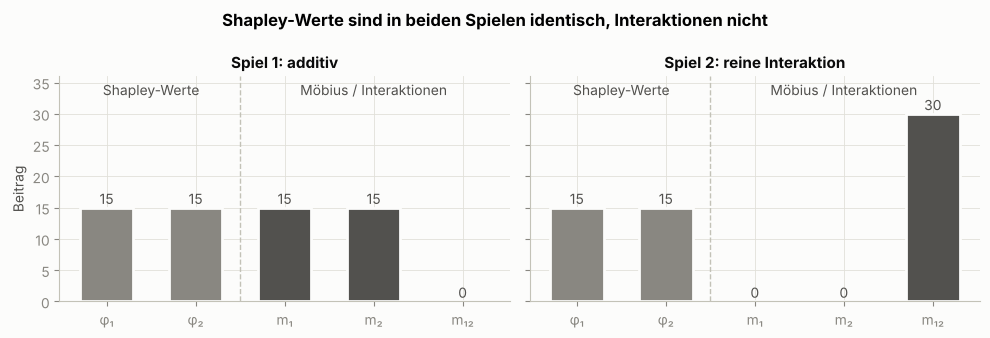

In [4]:
games = {"Spiel 1: additiv": np.array([0, 15, 15, 30.]), "Spiel 2: reine Interaktion": np.array([0, 0, 0, 30.])}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (title, v) in zip(axes, games.items()):
    m = moebius(v, 2)
    phi = shapley_values(m, 2)
    labels = ["φ₁", "φ₂", "m₁", "m₂", "m₁₂"]
    vals = [phi[0], phi[1], m[1], m[2], m[3]]
    cols = [C["muted"]] * 2 + [C["ink2"]] * 3  # neutral: Blau ist für EU reserviert
    bars = ax.bar(labels, vals, color=cols, width=0.6, edgecolor=C["surface"], linewidth=2)
    for b, val in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.6, f"{val:.0f}", ha="center", color=C["ink2"])
    ax.axvline(1.5, color="#c3c2b7", lw=1, ls="--")
    ax.set_title(title)
    ax.text(0.5, 33, "Shapley-Werte", ha="center", color=C["ink2"])
    ax.text(3, 33, "Möbius / Interaktionen", ha="center", color=C["ink2"])
    ax.set_ylim(0, 36)
axes[0].set_ylabel("Beitrag")
fig.suptitle("Shapley-Werte sind in beiden Spielen identisch, Interaktionen nicht", fontweight="bold")
plt.tight_layout(); plt.show()

**Merksatz:** Shapley-Werte sagen *wie viel*, Interaktionen sagen *wodurch*.

Für unsere Leitfrage heißt das: Ein Shapley-Wert von +0.15 für „Alter“ kann bedeuten „das Alter allein macht unsicher“ **oder** „nur die Kombination mit der Berufserfahrung macht unsicher“. Erst $m_{12}$ bzw. ein Interaktionsindex unterscheidet die beiden Fälle.

# 4 · Unsicherheit zerlegen: TU = AU + EU

Ein Ensemble aus $M$ Modellen liefert pro Punkt $M$ Verteilungen $p_1(y\mid x), \dots, p_M(y\mid x)$. In probly ist das eine **Repräsentation**. Die Entropie-Zerlegung (in probly: `SecondOrderEntropyDecomposition`) lautet:

$$
\underbrace{H\!\Bigl(\tfrac{1}{M}\textstyle\sum_m p_m\Bigr)}_{\text{TU: Entropie der Mittelverteilung}}
\;=\;
\underbrace{\tfrac{1}{M}\textstyle\sum_m H(p_m)}_{\text{AU: mittlere Entropie}}
\;+\;
\underbrace{\mathrm{TU} - \mathrm{AU}}_{\text{EU: Mutual Information}}
$$

- **AU hoch:** Jedes einzelne Modell ist unsicher (z. B. 50/50). Die Daten sind dort verrauscht, und mehr Daten helfen nicht.
- **EU hoch:** Die Modelle sind einzeln sicher, aber **uneinig**. Es fehlt Wissen, und mehr Daten würden helfen.

Wir messen in **Bit** (Logarithmus zur Basis 2). Bei zwei Klassen ist das Maximum 1 Bit.

,TU,AU,EU
alle sicher und einig,0.141,0.141,-0.000
alle 50/50 (Rauschen),1.000,1.000,0.000
"sicher, aber uneinig (Wissenslücke)",1.000,0.141,0.859


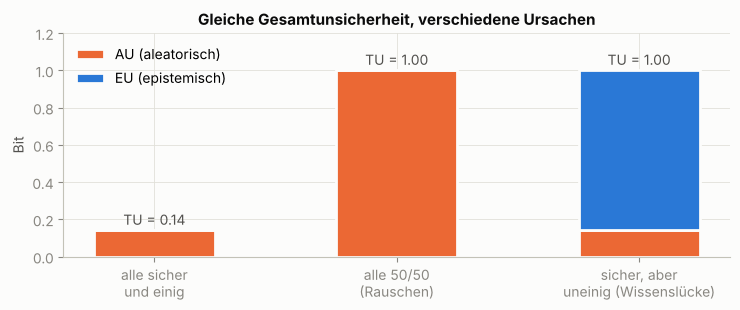

In [5]:
def entropy(p, axis=-1):
    """Shannon-Entropie in Bit."""
    p = np.clip(p, 1e-12, 1.0)
    return -(p * np.log2(p)).sum(axis=axis)

def decompose(P):
    """Entropie-Zerlegung. P: (M, ..., C) Wahrscheinlichkeiten pro Member -> (TU, AU, EU)."""
    tu = entropy(P.mean(axis=0))
    au = entropy(P).mean(axis=0)
    return tu, au, tu - au

def two_class(p1):
    return np.stack([1 - np.asarray(p1), np.asarray(p1)], axis=-1)

szenarien = {
    "alle sicher\nund einig": two_class([0.98] * 10),
    "alle 50/50\n(Rauschen)": two_class([0.5] * 10),
    "sicher, aber\nuneinig (Wissenslücke)": two_class([0.98] * 5 + [0.02] * 5),
}
rows = {name: dict(zip(["TU", "AU", "EU"], map(float, decompose(P)))) for name, P in szenarien.items()}
display(pd.DataFrame(rows).T.rename(index=lambda s: s.replace("\n", " ")))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
x = np.arange(len(rows))
au = np.array([r["AU"] for r in rows.values()]); eu = np.array([r["EU"] for r in rows.values()])
ax.bar(x, au, 0.5, color=C["AU"], label="AU (aleatorisch)", edgecolor=C["surface"], linewidth=2)
ax.bar(x, eu, 0.5, bottom=au, color=C["EU"], label="EU (epistemisch)", edgecolor=C["surface"], linewidth=2)
for xi, a, e in zip(x, au, eu):
    ax.text(xi, a + e + 0.03, f"TU = {a + e:.2f}", ha="center", color=C["ink2"])
ax.set_xticks(x, list(rows)); ax.set_ylabel("Bit"); ax.set_ylim(0, 1.2)
ax.set_title("Gleiche Gesamtunsicherheit, verschiedene Ursachen"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Die Szenarien 2 und 3 haben **dieselbe** totale Unsicherheit (≈ 1 Bit), aber völlig verschiedene Ursachen. Genau diese Unterscheidung wollen wir später **pro Merkmal und pro Merkmalspaar** erklären.

**Wichtig für später:** Die Zerlegung ist **additiv**, also TU = AU + EU für jede einzelne Repräsentation. Zusammen mit der Linearität der Shapley-Werte (Abschnitt 2) folgt daraus, dass auch die Erklärungen additiv sind.

# 5 · TwoMoons und ein Ensemble

**Warum TwoMoons?**
- Nur **2 Merkmale**: Man kann den *gesamten* Merkmalsraum als Bild zeigen. Das ist ideal für Karten und Präsentationsfolien.
- Die Daten liegen auf zwei gebogenen Bändern. Viele Kombinationen (x₁, x₂) kommen **nie** vor, obwohl jeder Einzelwert normal ist. Das ist eine eingebaute epistemische Interaktion.
- Zwischen den Bändern überlappen die Klassen durch Rauschen. Das ergibt aleatorische Unsicherheit.

**Ensemble:** 10 kleine neuronale Netze (`MLPClassifier`), jedes auf einer Bootstrap-Stichprobe mit eigenem Seed trainiert. Das entspricht dem, was `probly`s `ensemble` mit sklearn-Modellen tut.

10 Member, Trainingsgenauigkeit 0.960 bis 0.985


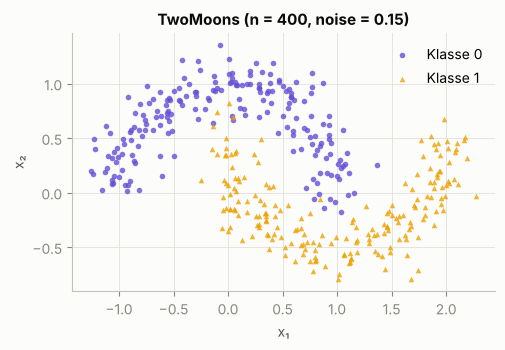

In [6]:
X, y = make_moons(n_samples=400, noise=0.15, random_state=SEED)

class Ensemble:
    """Minimaler Ersatz für eine probly-Ensemble-Repräsentation: liefert (M, n, C)."""
    def __init__(self, members):
        self.members = members
    def predict_members(self, Z):
        return np.stack([m.predict_proba(Z) for m in self.members])

def train_ensemble(X, y, M=10, hidden=(32, 32), alpha=1e-4, seed=SEED):
    members = []
    for m in range(M):
        idx = np.random.default_rng(seed + 100 + m).integers(0, len(X), len(X))  # Bootstrap
        clf = MLPClassifier(hidden_layer_sizes=hidden, alpha=alpha, max_iter=2000, random_state=seed + m)
        members.append(clf.fit(X[idx], y[idx]))
    return Ensemble(members)

ens = train_ensemble(X, y)
acc = [(mem.predict(X) == y).mean() for mem in ens.members]
print(f"{len(ens.members)} Member, Trainingsgenauigkeit {min(acc):.3f} bis {max(acc):.3f}")

def scatter_data(ax, X, y, s=10, alpha=0.8):
    ax.scatter(*X[y == 0].T, s=s, c=C["class0"], marker="o", alpha=alpha, label="Klasse 0", linewidths=0)
    ax.scatter(*X[y == 1].T, s=s, c=C["class1"], marker="^", alpha=alpha, label="Klasse 1", linewidths=0)

fig, ax = plt.subplots(figsize=(6, 3.6))
scatter_data(ax, X, y, s=16)
ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.set_title("TwoMoons (n = 400, noise = 0.15)"); ax.legend(loc="upper right")
ax.set_aspect("equal"); plt.tight_layout(); plt.show()

### Erste Unsicherheitskarte, noch ohne Shapley

Für jeden Punkt eines Gitters berechnen wir TU, AU und EU direkt aus dem Ensemble. Das ist die Karte, die probly allein liefern kann. Sie zeigt **wo** das Modell unsicher ist, aber noch nicht **warum**.

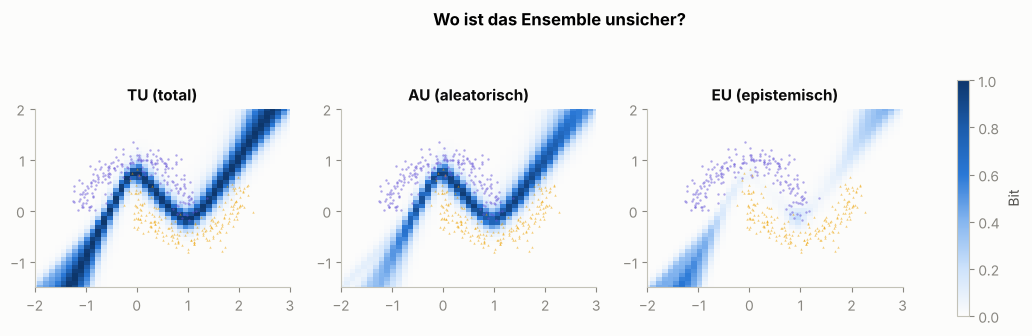

Max. EU auf dem Gitter: 0.63 Bit, max. AU: 0.97 Bit


In [7]:
XLIM, YLIM, RES = (-2.0, 3.0), (-1.5, 2.0), 45
gx, gy = np.linspace(*XLIM, RES), np.linspace(*YLIM, RES)
GX, GY = np.meshgrid(gx, gy)
GRID = np.c_[GX.ravel(), GY.ravel()]

TU_g, AU_g, EU_g = decompose(ens.predict_members(GRID))

def map_panel(ax, Z, title, cmap=CMAP_SEQ, norm=None, vmin=None, vmax=None, data=True):
    im = ax.pcolormesh(GX, GY, Z.reshape(GX.shape), cmap=cmap, norm=norm, vmin=vmin, vmax=vmax, shading="auto")
    if data:
        scatter_data(ax, X, y, s=3, alpha=0.5)
    ax.set_title(title); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
    return im

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, Z, t in zip(axes, [TU_g, AU_g, EU_g], ["TU (total)", "AU (aleatorisch)", "EU (epistemisch)"]):
    im = map_panel(ax, Z, t, vmin=0, vmax=1)
fig.colorbar(im, ax=axes, shrink=0.85, label="Bit")
fig.suptitle("Wo ist das Ensemble unsicher?", fontweight="bold", y=1.02)
plt.show()
print(f"Max. EU auf dem Gitter: {EU_g.max():.2f} Bit, max. AU: {AU_g.max():.2f} Bit")

**Lesart:**
- **AU** ist entlang der Entscheidungsgrenze hoch, also dort, wo sich die Monde durch Rauschen überlappen. Dort sind sich alle Member einig, *dass* es 50/50 steht.
- **EU** ist in Regionen **ohne Trainingsdaten** hoch, vor allem dort, wo die Entscheidungsgrenze ins Leere verlängert wird (unten links, oben rechts). Dort extrapoliert jedes Netz anders.
- **Auffällig:** Auch oben rechts, wo es *keine* Daten gibt, ist AU hoch. Dort verläuft die extrapolierte Grenze, und alle Member sagen ≈ 50/50 voraus. Das Ensemble hält die Wissenslücke also teilweise für Rauschen, eine bekannte Grenze der Entropie-Zerlegung. Unser Punkt P3 liegt genau in dieser Region.

Die Karte beantwortet **wo**. Für **warum**, also welches Merkmal oder welche Kombination, brauchen wir das Unsicherheitsspiel.

# 6 · Das Unsicherheitsspiel (unsere Kernidee)

**Problem:** Ein shapiq-Imputer mittelt *skalare* Modellausgaben. Wir haben aber pro Punkt eine *Sammlung von Verteilungen*, und Unsicherheit ist **nicht linear** (Entropie des Mittels ≠ Mittel der Entropien).

**Definition (Variante A aus dem Projektplan, Abschnitt 5):** Für einen Erklärpunkt $x$ und eine Koalition $S$ bekannter Merkmale:

1. Fehlende Merkmale $-S$ werden mit $K$ Hintergrundpunkten $x'^{(1)}, \dots, x'^{(K)}$ aufgefüllt.
2. **Pro Member** wird über die Imputationen gemittelt:
   $\displaystyle p_m(y \mid x_S) = \frac{1}{K}\sum_{k=1}^K p_m\bigl(y \mid x_S, x'^{(k)}_{-S}\bigr)$
3. Die Sammlung $\{p_m(y\mid x_S)\}_{m=1}^M$ ist wieder eine Repräsentation, und wir zerlegen sie:
   $\displaystyle v_{\mathrm{TU}}(S),\ v_{\mathrm{AU}}(S),\ v_{\mathrm{EU}}(S) = \texttt{decompose}\bigl(\{p_m(y\mid x_S)\}\bigr)$

Daraus entstehen **drei Spiele** und drei Erklärungen pro Punkt.

```
x ──► Maske S ──► K imputierte Punkte ──► M Member ──► Mittel über K (pro Member) ──► decompose ──► v_TU, v_AU, v_EU
```

### Implementierung

Vektorisiert über viele Erklärpunkte gleichzeitig, damit später ganze Karten in Sekunden berechnet werden. Die Varianten B und C (Designfrage D1) sind schon eingebaut und kommen in Abschnitt 9 zum Einsatz.

In [8]:
def marginal_impute(x_points, mask, background, K, rng):
    """Fehlende Merkmale aus K zufälligen Hintergrundpunkten (unabhängig von x). -> (n, K, d)"""
    B = background[rng.choice(len(background), size=K, replace=False)]
    return np.where(mask, x_points[:, None, :], B[None, :, :])

def uncertainty_game(ensemble, x_points, background, K=100, imputer=marginal_impute, variant="A", seed=SEED):
    """Wertet die drei Unsicherheitsspiele für alle 2**d Koalitionen aus.

    Returns: dict {"TU","AU","EU"} -> Array (2**d, n_points), nach Bitmaske indiziert.
    variant: "A" = pro Member über Imputationen mitteln, dann zerlegen
             "B" = pro imputiertem Punkt zerlegen, dann mitteln
             "C" = alle Member x Imputationen als ein großes Ensemble
    """
    x_points = np.atleast_2d(x_points)
    n, d = x_points.shape
    out = {k: np.zeros((2 ** d, n)) for k in ("TU", "AU", "EU")}
    for s in range(2 ** d):
        mask = coalition_mask(s, d)
        Z = imputer(x_points, mask, background, K, np.random.default_rng(seed))  # gleiche Hintergrundpunkte für alle S
        P = ensemble.predict_members(Z.reshape(n * K, d)).reshape(len(ensemble.members), n, K, -1)
        if variant == "A":
            tu, au, eu = decompose(P.mean(axis=2))
        elif variant == "B":
            tu, au, eu = (u.mean(axis=-1) for u in decompose(P))
        elif variant == "C":
            tu, au, eu = decompose(P.transpose(0, 2, 1, 3).reshape(-1, n, P.shape[-1]))
        out["TU"][s], out["AU"][s], out["EU"][s] = tu, au, eu
    return out

BACKGROUND = X  # Hintergrunddaten = Trainingsdaten

### Eigenschaften prüfen, bevor wir irgendetwas interpretieren

Diese Checks sind die Vorlage für unsere späteren **pytest-Tests** (`tests/...`):
1. **Effizienz:** $\sum_i \phi_i = v(N) - v(\emptyset)$
2. **Additivität der Erklärung:** $\phi_i(\mathrm{TU}) = \phi_i(\mathrm{AU}) + \phi_i(\mathrm{EU})$ (gilt *auch für Interaktionen*)
3. **Konsistenz:** $v(N)$ entspricht der direkten Zerlegung am Punkt (keine Imputation)

In [9]:
x_check = np.array([[0.5, 0.25], [2.0, 1.0], [-1.0, 0.2]])
v = uncertainty_game(ens, x_check, BACKGROUND)
m = {k: moebius(v[k], 2) for k in v}
phi = {k: np.array([shapley_values(m[k][:, p], 2) for p in range(len(x_check))]) for k in v}

eff = max(abs(phi[k].sum(1) - (v[k][-1] - v[k][0])).max() for k in v)
add_sv = abs(phi["TU"] - phi["AU"] - phi["EU"]).max()
add_int = abs(m["TU"][3] - m["AU"][3] - m["EU"][3]).max()
direct = np.array(decompose(ens.predict_members(x_check)))
cons = abs(np.array([v["TU"][-1], v["AU"][-1], v["EU"][-1]]) - direct).max()

print(f"Effizienz           max. Fehler {eff:.1e}")
print(f"φ(TU) = φ(AU)+φ(EU)  max. Fehler {add_sv:.1e}")
print(f"m₁₂ additiv          max. Fehler {add_int:.1e}")
print(f"v(N) = direkt        max. Fehler {cons:.1e}")

Effizienz           max. Fehler 1.1e-16
φ(TU) = φ(AU)+φ(EU)  max. Fehler 1.1e-16
m₁₂ additiv          max. Fehler 2.2e-16
v(N) = direkt        max. Fehler 3.2e-16


Alle Fehler liegen im Bereich der Rechengenauigkeit. **Die Zerlegung der Erklärung bekommen wir geschenkt.** Wir müssen nur die AU- und EU-Spiele erklären, die TU-Erklärung ist ihre Summe.

**Ein Nebenbefund für Designfrage D3 (Vorzeichen):** $v(\emptyset)$ ist bei Variante A ungefähr 1 Bit TU, und zwar fast vollständig **AU**. Ohne jedes Merkmal sagen alle Member gemittelt etwa die Klassen-Prior 50/50 voraus und sind sich darin *einig*. Bekannte Merkmale **senken** die Unsicherheit daher meist, und die Beiträge sind negativ. Bei EU ist es umgekehrt: $v_{\mathrm{EU}}(\emptyset) \approx 0$, und bekannte Merkmale können EU *erzeugen*.

# 7 · Einzelne Punkte erklären

Drei typische Punkte:

| Punkt | Lage | Erwartung |
|---|---|---|
| **P1** (−1.0, 0.2) | mitten im linken Mond | sicher, fast keine Unsicherheit |
| **P2** (0.5, 0.25) | zwischen den Monden, Überlappung | **aleatorisch** |
| **P3** (2.0, 1.0) | x₁ = 2 kommt vor, x₂ = 1 kommt vor, **die Kombination nicht** | **epistemisch, durch Interaktion** |

v(∅)  v(N)  φ₁ (Shapley)  ...     m₁     m₂  m₁₂ (Interaktion)
Punkt     Maß                            ...                                 
P1 sicher TU  0.998 0.001        -0.955  ... -0.912  0.000             -0.085
          AU  0.998 0.001        -0.961  ... -0.925 -0.001             -0.071
          EU  0.000 0.000         0.006  ...  0.013  0.001             -0.014
P2 Grenze TU  0.998 0.976        -0.014  ... -0.005  0.001             -0.019
          AU  0.998 0.948        -0.028  ... -0.007  0.000             -0.044
          EU  0.000 0.028         0.014  ...  0.002  0.001              0.025
P3 Lücke  TU  0.998 0.990         0.049  ... -0.550 -0.657              1.199
          AU  0.998 0.844        -0.030  ... -0.568 -0.661              1.075
          EU  0.000 0.146         0.080  ...  0.018  0.004              0.124

[9 rows x 7 columns]

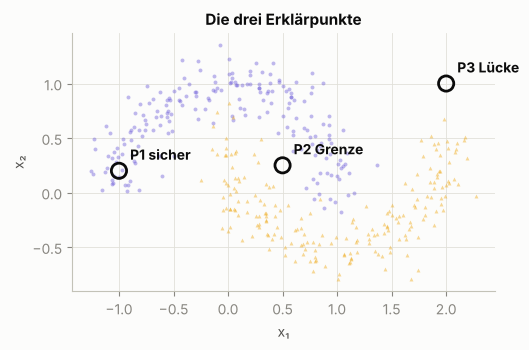

In [10]:
POINTS = {"P1 sicher": [-1.0, 0.2], "P2 Grenze": [0.5, 0.25], "P3 Lücke": [2.0, 1.0]}
XP = np.array(list(POINTS.values()))
vP = uncertainty_game(ens, XP, BACKGROUND)
mP = {k: moebius(vP[k], 2) for k in vP}

tab = []
for p, name in enumerate(POINTS):
    for k in ("TU", "AU", "EU"):
        sv = shapley_values(mP[k][:, p], 2)
        tab.append({"Punkt": name, "Maß": k, "v(∅)": vP[k][0, p], "v(N)": vP[k][3, p],
                    "φ₁ (Shapley)": sv[0], "φ₂ (Shapley)": sv[1],
                    "m₁": mP[k][1, p], "m₂": mP[k][2, p], "m₁₂ (Interaktion)": mP[k][3, p]})
display(pd.DataFrame(tab).set_index(["Punkt", "Maß"]))

fig, ax = plt.subplots(figsize=(6, 3.6))
scatter_data(ax, X, y, s=8, alpha=0.4)
for name, (px, py) in POINTS.items():
    ax.scatter(px, py, s=120, facecolor="none", edgecolor=C["ink"], linewidth=2)
    ax.annotate(name, (px, py), xytext=(8, 8), textcoords="offset points", fontweight="bold", color=C["ink"])
ax.set_aspect("equal"); ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.set_title("Die drei Erklärpunkte")
plt.tight_layout(); plt.show()

### Shapley-Werte vs. Interaktionen, nebeneinander

Oben: nur Shapley-Werte, also das, was ein Standard-Explainer zeigt. Unten: Haupteffekte und Interaktion. Balken unter 0 senken, über 0 erhöhen die jeweilige Unsicherheit.

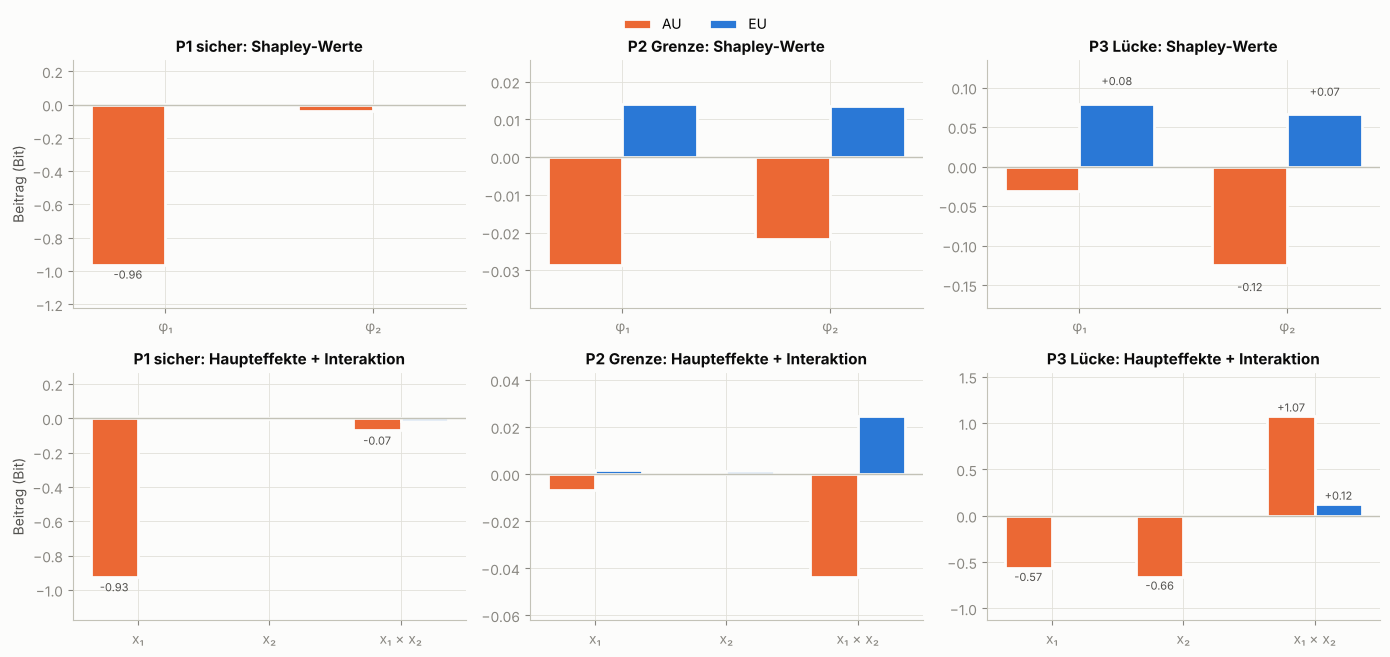

In [11]:
def explanation_bars(ax, vals_au, vals_eu, labels, title):
    x = np.arange(len(labels)); w = 0.36
    for off, vals, k in [(-w / 2, vals_au, "AU"), (w / 2, vals_eu, "EU")]:
        bars = ax.bar(x + off, vals, w, color=C[k], label=k, edgecolor=C["surface"], linewidth=2)
        for b, val in zip(bars, vals):
            if abs(val) >= 0.05:
                ax.text(b.get_x() + b.get_width() / 2, val + (0.02 if val >= 0 else -0.02), f"{val:+.2f}",
                        ha="center", va="bottom" if val >= 0 else "top", fontsize=8, color=C["ink2"])
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_xticks(x, labels); ax.set_title(title)

fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
for p, name in enumerate(POINTS):
    sv_au, sv_eu = shapley_values(mP["AU"][:, p], 2), shapley_values(mP["EU"][:, p], 2)
    explanation_bars(axes[0, p], sv_au, sv_eu, ["φ₁", "φ₂"], f"{name}: Shapley-Werte")
    explanation_bars(axes[1, p], [mP["AU"][s, p] for s in (1, 2, 3)], [mP["EU"][s, p] for s in (1, 2, 3)],
                     ["x₁", "x₂", "x₁ × x₂"], f"{name}: Haupteffekte + Interaktion")
for a in axes.ravel():  # eigene Skala pro Panel, sonst verschwinden kleine Effekte (P2)
    lo, hi = a.get_ylim(); lo, hi = min(lo, 0), max(hi, 0); pad = 0.2 * (hi - lo)
    a.set_ylim(lo - pad, hi + pad)
axes[0, 0].set_ylabel("Beitrag (Bit)"); axes[1, 0].set_ylabel("Beitrag (Bit)")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.show()

**Was man sieht (Zahlen siehe Tabelle oben):**

- **P1 (sicher):** Ein großer **negativer AU-Beitrag**, fast ausschließlich von x₁. Bei x₁ = −1 gibt es nur den linken Mond, x₁ allein entscheidet also die Klasse und nimmt die Basisunsicherheit von ≈ 1 Bit weg. EU ist praktisch null.
- **P2 (Grenze):** Fast alles ist **AU**, und die Beiträge sind klein, weil der Punkt auch mit allen Merkmalen nahe 50/50 bleibt. Mehr Wissen hilft hier nicht.
- **P3 (Lücke), die Kernaussage:** Die Shapley-Werte (oben) verteilen die EU **auf beide Merkmale**. Die Zerlegung unten zeigt, dass der Großteil der EU **nur aus der Kombination x₁ × x₂** stammt. Die Haupteffekte sind klein. Das ist exakt die „25 Jahre + 30 Jahre Erfahrung“-Situation.

Für P3 fällt außerdem auf: Die AU-Interaktion ist groß und **positiv**. Einzeln senken x₁ und x₂ die AU stark, zusammen heben sie diese Senkung wieder teilweise auf, weil der Punkt in einer Region liegt, in der die Member auch einzeln weniger sicher sind.

# 8 · Shapley-Unsicherheitskarten

**Idee:** Wir berechnen die Erklärung nicht für drei Punkte, sondern für **jeden Punkt eines Gitters**, und zeichnen jede Komponente als eigene Karte.

Bei zwei Merkmalen gibt es pro Unsicherheitsart genau drei Komponenten: $m_1$, $m_2$, $m_{12}$. Also entstehen **6 Karten** (AU und EU, TU ist deren Summe).

**Was eine Karte beantwortet:** *An welcher Stelle im Merkmalsraum treibt welches Merkmal (oder welche Kombination) welche Art von Unsicherheit?*

Kosten: 45 × 45 = 2025 Punkte × 4 Koalitionen × 100 Imputationen × 10 Member ≈ 8 Mio. Vorhersagen. Vektorisiert dauert das wenige Sekunden.

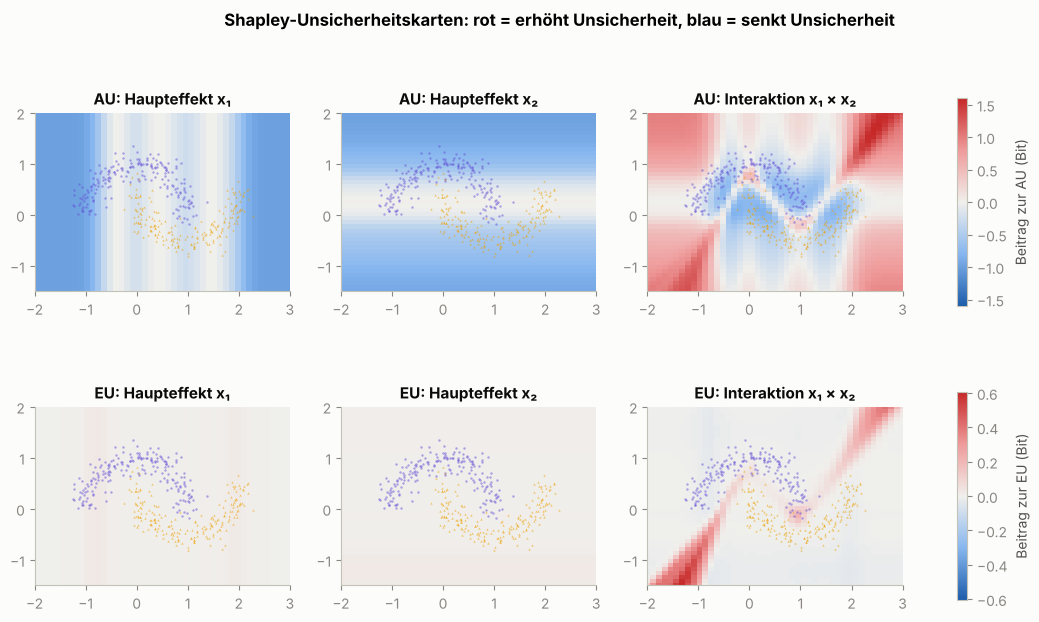

In [12]:
vG = uncertainty_game(ens, GRID, BACKGROUND, K=100)
mG = {k: moebius(vG[k], 2) for k in vG}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for r, k in enumerate(["AU", "EU"]):
    comps = [mG[k][1], mG[k][2], mG[k][3]]
    lim = max(abs(c).max() for c in comps)
    norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
    for c, (Z, lab) in enumerate(zip(comps, ["Haupteffekt x₁", "Haupteffekt x₂", "Interaktion x₁ × x₂"])):
        im = map_panel(axes[r, c], Z, f"{k}: {lab}", cmap=CMAP_DIV, norm=norm)
    fig.colorbar(im, ax=axes[r], shrink=0.85, label=f"Beitrag zur {k} (Bit)")
fig.suptitle("Shapley-Unsicherheitskarten: rot = erhöht Unsicherheit, blau = senkt Unsicherheit", fontweight="bold")
plt.show()

**Lesart der Karten:**

- **EU-Zeile:** Die rote Fläche liegt fast ausschließlich in der **Interaktionskarte** (rechts). Die Haupteffekte x₁ und x₂ sind im Vergleich blass. *Die epistemische Unsicherheit auf TwoMoons ist im Kern eine Interaktion:* Die Werte einzeln sind bekannt, ihre Kombination nicht.
- **AU-Zeile:** Die Haupteffekte sind überwiegend blau, denn einzelne Merkmale senken die Basisunsicherheit von ≈ 1 Bit. Ausnahmen sind Streifen, in denen ein Wert allein nichts verrät (x₁ zwischen 0 und 1, wo beide Monde liegen). Die Interaktion ist **auf den Monden blau** (erst die Kombination macht ganz sicher) und **rot** entlang der Grenze und in leeren Ecken, also dort, wo die Kombination die Senkung durch die Einzelmerkmale wieder aufhebt.

Die nächste Karte verdichtet die Frage „Wie viel der EU ist Interaktion?“ auf eine einzige Zahl pro Punkt.

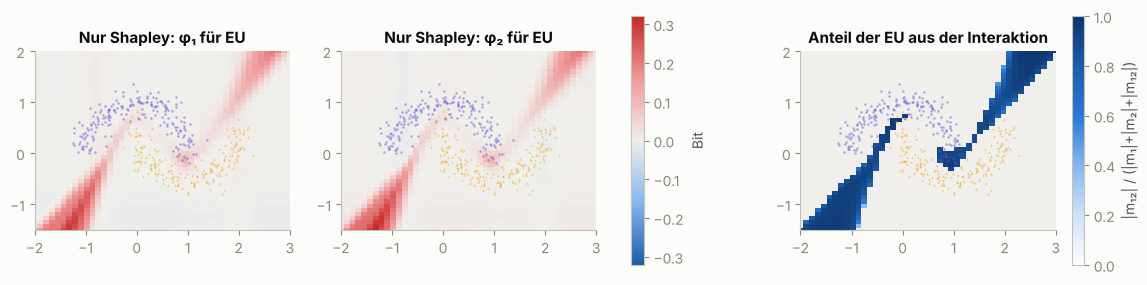

Punkte mit EU > 0.05 Bit: 264 von 2025
Davon mit Interaktionsanteil > 50 %: 99% (Median-Anteil 92%)


In [13]:
eu_N = vG["EU"][3]
denom = abs(mG["EU"][1]) + abs(mG["EU"][2]) + abs(mG["EU"][3])
share = np.where(eu_N > 0.05, abs(mG["EU"][3]) / np.maximum(denom, 1e-12), np.nan)
phi_g = np.array([shapley_values(mG["EU"][:, p], 2) for p in range(len(GRID))])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
lim = abs(phi_g).max(); norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
map_panel(axes[0], phi_g[:, 0], "Nur Shapley: φ₁ für EU", cmap=CMAP_DIV, norm=norm)
im0 = map_panel(axes[1], phi_g[:, 1], "Nur Shapley: φ₂ für EU", cmap=CMAP_DIV, norm=norm)
fig.colorbar(im0, ax=axes[:2], shrink=0.85, label="Bit")
cm = CMAP_SEQ.copy(); cm.set_bad("#f0efec")
im = map_panel(axes[2], share, "Anteil der EU aus der Interaktion", cmap=cm, vmin=0, vmax=1)
fig.colorbar(im, ax=axes[2], shrink=0.85, label="|m₁₂| / (|m₁|+|m₂|+|m₁₂|)")
plt.show()
valid = ~np.isnan(share)
print(f"Punkte mit EU > 0.05 Bit: {valid.sum()} von {len(share)}")
print(f"Davon mit Interaktionsanteil > 50 %: {(share[valid] > 0.5).mean():.0%} (Median-Anteil {np.median(share[valid]):.0%})")

**Die zentrale Gegenüberstellung für eine Präsentationsfolie:**

- Links und Mitte, *nur Shapley-Werte*: Die beiden Karten sehen fast **gleich** aus. Man würde folgern, dass x₁ und x₂ gleichermaßen schuld sind.
- Rechts: Wo das Modell epistemisch unsicher ist (grau = kaum EU), stammt der **überwiegende Anteil aus der Interaktion**.

> **Eine Frage, ein Bild, eine Antwort:** *Warum ist das Modell hier unsicher?* Weil diese **Kombination** von Werten nie gesehen wurde, nicht weil ein einzelner Wert ungewöhnlich ist.

# 9 · Designfrage D1: Erst mitteln oder erst messen?

Wie werden die $M \times K$ Vorhersagen (Member × Imputationen) zu *einer* Repräsentation?

| Variante | Rechnung | Wohin wandert die Streuung durch Imputation? |
|---|---|---|
| **A** | pro Member über $K$ mitteln, dann zerlegen | in die **AU** |
| **B** | pro imputiertem Punkt zerlegen, dann TU/AU/EU mitteln | wird gar nicht als Unsicherheit gezählt |
| **C** | alle $M \cdot K$ als ein großes Ensemble | in die **EU** |

**Aus der Konkavität der Entropie (Jensen) folgt sofort:**
- $\mathrm{TU}_A = \mathrm{TU}_C$ (gleiche Mittelverteilung)
- $\mathrm{AU}_A \ge \mathrm{AU}_C = \mathrm{AU}_B$ (Entropie des Mittels ≥ Mittel der Entropien)
- also $\mathrm{EU}_A \le \mathrm{EU}_C$

Variante C erzeugt also systematisch **mehr** epistemische Unsicherheit. Wie viel, zeigt der Vergleich für P3:

Variante,A,B,C
v_EU(S) für P3,,,
∅,0.000,0.008,0.902
{x₁},0.018,0.029,0.249
{x₂},0.004,0.015,0.239
"{x₁,x₂}",0.146,0.146,0.146


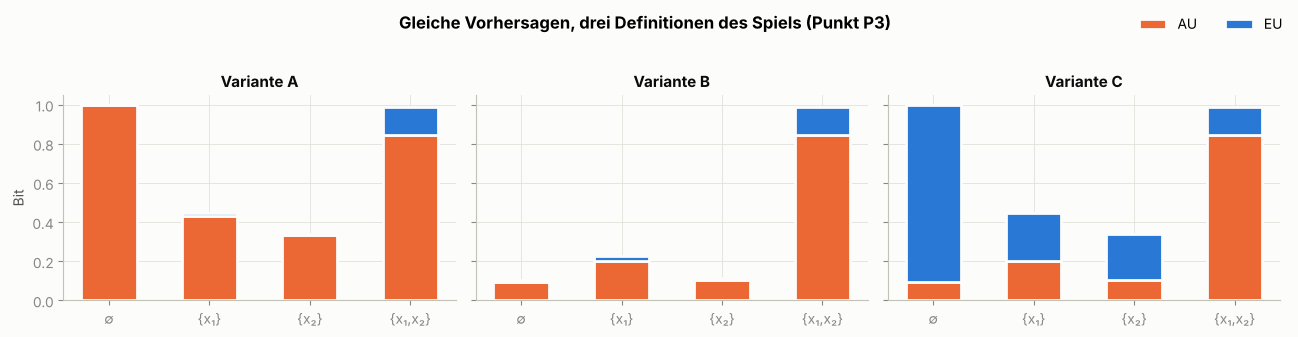

In [14]:
rows = []
for var in "ABC":
    vv = uncertainty_game(ens, XP[2:3], BACKGROUND, variant=var)
    for s, lab in enumerate(["∅", "{x₁}", "{x₂}", "{x₁,x₂}"]):
        rows.append({"Variante": var, "Koalition": lab, "TU": vv["TU"][s, 0], "AU": vv["AU"][s, 0], "EU": vv["EU"][s, 0]})
d1 = pd.DataFrame(rows)
display(d1.pivot(index="Koalition", columns="Variante", values="EU").loc[["∅", "{x₁}", "{x₂}", "{x₁,x₂}"]].rename_axis("v_EU(S) für P3"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, var in zip(axes, "ABC"):
    sub = d1[d1.Variante == var]
    ax.bar(sub.Koalition, sub.AU, 0.55, color=C["AU"], label="AU", edgecolor=C["surface"], linewidth=2)
    ax.bar(sub.Koalition, sub.EU, 0.55, bottom=sub.AU, color=C["EU"], label="EU", edgecolor=C["surface"], linewidth=2)
    ax.set_title(f"Variante {var}")
axes[0].set_ylabel("Bit")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1.0, 1.06))
fig.suptitle("Gleiche Vorhersagen, drei Definitionen des Spiels (Punkt P3)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**Interpretation:**
- **Variante C** meldet schon für die leere Koalition fast **1 Bit EU**. Die Uneinigkeit zwischen *verschiedenen Hintergrundpunkten* wird als Modell-Uneinigkeit gezählt. Das ist ein Artefakt.
- **Variante B** startet bei sehr kleiner TU, denn sie misst „wie unsicher ist das Modell im Mittel auf Hintergrundpunkten“, nicht „wie unsicher ist es über $y$, wenn ich $x_{-S}$ nicht kenne“.
- **Variante A** hat die natürlichste Lesart: Nicht-Wissen über fehlende Merkmale ist für die Vorhersage *Rauschen* (AU), echte Modell-Uneinigkeit bleibt EU.

→ Das spricht für A als Standard. Offen ist, mit welcher Variante Watson et al. (2023) arbeiten; das sollten wir beim Lesen gezielt prüfen. Ein **axiomatischer Vergleich** der Varianten wäre die Projektidee N3.

# 10 · Designfrage D2: Das Imputationsartefakt

**Problem:** Marginale Imputation kombiniert $x_S$ mit *beliebigen* Hintergrundwerten. Die entstehenden Punkte liegen oft **abseits der Daten**, also genau dort, wo das Ensemble uneinig ist. Die Erklärmethode **erzeugt dann selbst epistemische Unsicherheit**.

Für Interaktionen ist das besonders heikel: Wir wollen „ungesehene Kombinationen“ entdecken, und marginale Imputation **produziert** ungesehene Kombinationen.

**Gegenmittel:** **Bedingte** Imputation, also fehlende Merkmale nur aus Hintergrundpunkten ziehen, die in den bekannten Merkmalen ähnlich sind. Hier die einfachste Variante: **k nächste Nachbarn** in den bekannten Merkmalen. shapiq bietet dafür u. a. Gaussian-Copula- und Generative-Conditional-Imputer.

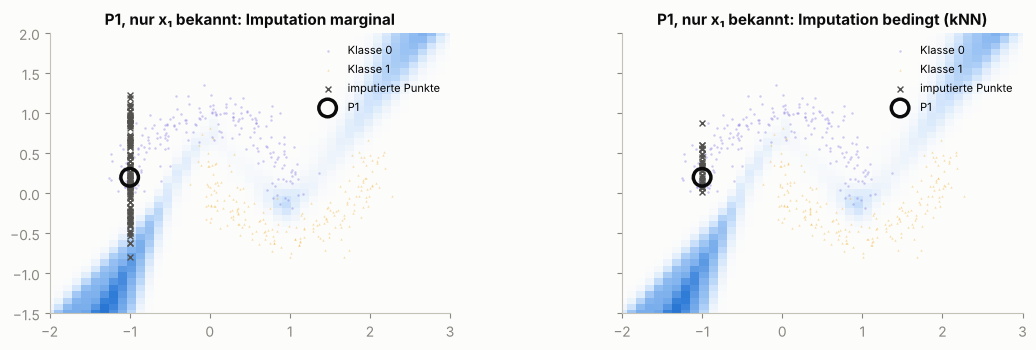

In [15]:
def conditional_impute(x_points, mask, background, K, rng):
    """kNN-bedingte Imputation: fehlende Merkmale von den K nächsten Nachbarn in den bekannten Merkmalen."""
    if mask.all():
        return np.repeat(x_points[:, None, :], K, axis=1)
    if not mask.any():
        return marginal_impute(x_points, mask, background, K, rng)
    sd = background.std(axis=0)
    D = (((x_points[:, None, mask] - background[None, :, mask]) / sd[mask]) ** 2).sum(-1)
    nn = np.argsort(D, axis=1)[:, :K]
    return np.where(mask, x_points[:, None, :], background[nn])

# Wo landen die imputierten Punkte für P1 mit Koalition {x₁}?
x1_only = coalition_mask(0b01, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, (imp, title, K) in zip(axes, [(marginal_impute, "marginal", 100), (conditional_impute, "bedingt (kNN)", 30)]):
    Z = imp(XP[:1], x1_only, BACKGROUND, K, np.random.default_rng(SEED))[0]
    map_panel(ax, EU_g, f"P1, nur x₁ bekannt: Imputation {title}", vmin=0, vmax=1, data=False)
    scatter_data(ax, X, y, s=3, alpha=0.3)
    ax.scatter(*Z.T, s=18, c=C["ink2"], marker="x", linewidths=1, label="imputierte Punkte")
    ax.scatter(*XP[0], s=160, facecolor="none", edgecolor=C["ink"], linewidth=2.5, label="P1")
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

Links liegen die imputierten Punkte auf einer **senkrechten Linie** quer durch den Raum, darunter etliche Punkte unterhalb des Mondes, wo es keine Daten gibt, teils schon am Rand der Region hoher EU (Hintergrund: EU-Karte). Rechts bleiben sie **auf dem linken Mond**, also dort, wo $x_1 = -1$ tatsächlich vorkommt.

Wie stark verfälscht das die Erklärungen? Vergleich auf 200 frischen Punkten **aus der Datenverteilung**, wo das Modell eigentlich kaum epistemisch unsicher sein sollte:

In [16]:
X_test, _ = make_moons(200, noise=0.15, random_state=1)
res = {}
for name, imp, K in [("marginal", marginal_impute, 100), ("bedingt (kNN)", conditional_impute, 30)]:
    vv = uncertainty_game(ens, X_test, BACKGROUND, K=K, imputer=imp)
    mm = moebius(vv["EU"], 2)
    sv = np.array([shapley_values(mm[:, p], 2) for p in range(len(X_test))])
    res[name] = {"EU am Punkt  v(N)": vv["EU"][3].mean(), "EU mit nur x₁  v({x₁})": vv["EU"][1].mean(),
                 "EU mit nur x₂  v({x₂})": vv["EU"][2].mean(), "mittl. |φ₁|": abs(sv[:, 0]).mean(),
                 "mittl. |φ₂|": abs(sv[:, 1]).mean(), "mittl. |m₁₂|": abs(mm[3]).mean()}
d2 = pd.DataFrame(res)
display(d2.rename_axis("Mittel über 200 Testpunkte (Bit)"))
r = d2.loc["mittl. |φ₁|", "marginal"] / d2.loc["mittl. |φ₁|", "bedingt (kNN)"]
print(f"Marginal erklärt im Mittel {r:.1f}× so viel EU für x₁ wie bedingt, obwohl v(N) identisch ist.")

,marginal,bedingt (kNN)
Mittel über 200 Testpunkte (Bit),,
EU am Punkt v(N),0.006,0.006
EU mit nur x₁ v({x₁}),0.007,0.002
EU mit nur x₂ v({x₂}),0.003,0.003
mittl. |φ₁|,0.006,0.004
mittl. |φ₂|,0.005,0.004
mittl. |m₁₂|,0.013,0.008


Marginal erklärt im Mittel 1.4× so viel EU für x₁ wie bedingt, obwohl v(N) identisch ist.


**Befund:**
- Mit nur x₁ bekannt meldet marginale Imputation im Mittel sogar etwas **mehr EU als mit beiden Merkmalen** (0.007 vs. 0.006 Bit). Weniger Wissen über den Punkt erzeugt scheinbar mehr *Modell*-Uneinigkeit. Das ist das Artefakt: Die Unsicherheit stammt aus den künstlichen Punkten.
- Bedingt sinkt dieser Wert auf 0.002 Bit, und die Erklärungsbeträge werden kleiner (|φ₁| um etwa ein Drittel, |m₁₂| um etwa 40 %).
- **Ehrliche Einordnung:** Absolut ist der Effekt hier klein, weil EU auf der Datenverteilung generell klein ist. Wie groß er bei echten Datensätzen mit vielen, stark abhängigen Merkmalen wird, ist offen, und genau das würde N2 messen.

Und für P3, den eigentlichen Lückenpunkt:

In [17]:
rows = {}
for name, imp, K in [("marginal", marginal_impute, 100), ("bedingt (kNN)", conditional_impute, 30)]:
    mm = moebius(uncertainty_game(ens, XP[2:3], BACKGROUND, K=K, imputer=imp)["EU"], 2)[:, 0]
    rows[name] = {"m₁ (x₁)": mm[1], "m₂ (x₂)": mm[2], "m₁₂ (x₁ × x₂)": mm[3]}
display(pd.DataFrame(rows).T.rename_axis("EU-Zerlegung für P3"))

,m₁ (x₁),m₂ (x₂),m₁₂ (x₁ × x₂)
EU-Zerlegung für P3,,,
marginal,0.018,0.004,0.124
bedingt (kNN),0.001,0.002,0.144


Mit bedingter Imputation wird das Bild **noch klarer**: Die Haupteffekte verschwinden fast vollständig, und die EU von P3 ist nahezu **reine Interaktion**.

**Aber:** kNN-Imputation funktioniert bei 2 Merkmalen gut, wird bei vielen Merkmalen jedoch schwierig (Fluch der Dimension), und bei sehr seltenen Werten gibt es keine echten Nachbarn. Daraus lässt sich die Projektidee **N2** machen: das Artefakt quantifizieren und einen unsicherheitskonsistenten Imputer vorschlagen.

# 11 · Benchmark mit eingebauter Ground Truth (Projektidee N1)

TwoMoons hat nur 2 Merkmale. Für einen **überprüfbaren** Benchmark bauen wir Effekte gezielt ein:

| Merkmal | Konstruktion | Erwartung (Ground Truth) |
|---|---|---|
| **x₁, x₂** | TwoMoons-Koordinaten | Lücken in der gemeinsamen Verteilung → **EU-Interaktion x₁ × x₂** |
| **x₃** | $\sim U(0, 1)$, Label wird mit Wahrscheinlichkeit $0.45 \cdot x_3$ vertauscht | steuert das Rauschen → **AU**, Vorzeichen abhängig vom Wert |
| **x₄** | $\sim N(0, 1)$, völlig unabhängig | **Dummy**, Beiträge ≈ 0 |

Mit 4 Merkmalen gibt es $2^4 = 16$ Koalitionen, das ist weiterhin exakt berechenbar.

In [18]:
N4 = 3000
r4 = np.random.default_rng(SEED)
Xm, y4 = make_moons(N4, noise=0.12, random_state=SEED)
x3 = r4.uniform(0, 1, N4)
x4 = r4.normal(0, 1, N4)
y4 = np.where(r4.uniform(size=N4) < 0.45 * x3, 1 - y4, y4)  # x₃ steuert das Label-Rauschen
X4 = np.c_[Xm, x3, x4]
FEAT = ["x₁", "x₂", "x₃ (Rauschen)", "x₄ (Dummy)"]

ens4 = train_ensemble(X4, y4, alpha=1e-4)
print("Ensemble auf 4 Merkmalen trainiert.")

P4 = {"Q1 Lücke, wenig Rauschen": [2.0, 1.0, 0.1, 0.0],
      "Q2 auf dem Mond, viel Rauschen": [0.0, 1.0, 0.95, 0.0],
      "Q3 auf dem Mond, wenig Rauschen": [0.0, 1.0, 0.05, 0.0]}
XQ = np.array(list(P4.values()))
vQ = uncertainty_game(ens4, XQ, X4, K=100)
mQ = {k: moebius(vQ[k], 4) for k in vQ}
tu, au, eu = decompose(ens4.predict_members(XQ))
display(pd.DataFrame({"TU": tu, "AU": au, "EU": eu}, index=list(P4)).rename_axis("direkt am Punkt (Bit)"))

Ensemble auf 4 Merkmalen trainiert.


,TU,AU,EU
direkt am Punkt (Bit),,,
"Q1 Lücke, wenig Rauschen",0.983,0.681,0.302
"Q2 auf dem Mond, viel Rauschen",0.999,0.979,0.020
"Q3 auf dem Mond, wenig Rauschen",0.147,0.135,0.012


### Interaktionsmatrizen (STII, Ordnung 2)

Diagonale = Haupteffekte, außerhalb = Paar-Interaktionen. Pro Punkt eine Matrix für AU und eine für EU.

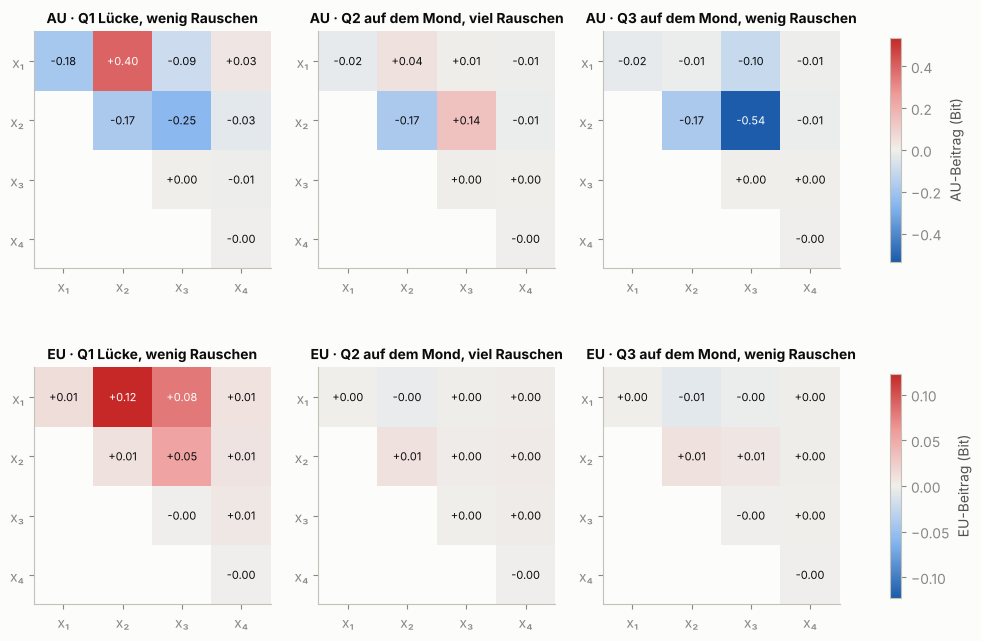

In [19]:
def stii_matrix(m, d):
    st = stii_order2(m, d); Mx = np.zeros((d, d))
    for key, val in st.items():
        i, j = (key[0], key[0]) if len(key) == 1 else key
        Mx[i, j] = Mx[j, i] = val
    return Mx

short = ["x₁", "x₂", "x₃", "x₄"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for r, k in enumerate(["AU", "EU"]):
    mats = [stii_matrix(mQ[k][:, p], 4) for p in range(len(XQ))]
    lim = max(abs(Mx).max() for Mx in mats); norm = TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim)
    for c, (Mx, name) in enumerate(zip(mats, P4)):
        ax = axes[r, c]
        im = ax.imshow(np.where(np.tril(np.ones((4, 4)), -1) == 1, np.nan, Mx), cmap=CMAP_DIV, norm=norm)
        for i in range(4):
            for j in range(4):
                if j >= i:
                    ax.text(j, i, f"{Mx[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                            color="white" if abs(Mx[i, j]) > 0.6 * lim else C["ink"])
        ax.set_xticks(range(4), short); ax.set_yticks(range(4), short); ax.grid(False)
        ax.set_title(f"{k} · {name}", fontsize=10)
    fig.colorbar(im, ax=axes[r], shrink=0.8, label=f"{k}-Beitrag (Bit)")
plt.show()

In [20]:
# Größte Möbius-Effekte (alle Ordnungen) der EU für Q1
mq = mQ["EU"][:, 0]
top = sorted(range(1, 16), key=lambda s: -abs(mq[s]))[:6]
display(pd.DataFrame({"Koalition": ["{" + ", ".join(short[j] for j in range(4) if (s >> j) & 1) + "}" for s in top],
                      "Ordnung": [popcount(s) for s in top], "Möbius m(S) für EU": [mq[s] for s in top]}).set_index("Koalition"))

# Gegenprobe: derselbe Lückenpunkt, nur das Rauschen x₃ variiert
for x3_val in (0.05, 0.5, 0.95):
    _, _, eu_x3 = decompose(ens4.predict_members(np.array([[2.0, 1.0, x3_val, 0.0]])))
    print(f"Lückenpunkt (2.0, 1.0) mit x₃ = {x3_val:.2f}:  EU = {eu_x3[0]:.3f} Bit")

,Ordnung,Möbius m(S) für EU
Koalition,,
"{x₁, x₂, x₃}",3,0.122
"{x₁, x₂}",2,0.074
"{x₁, x₃}",2,0.033
"{x₁, x₂, x₃, x₄}",4,0.025
{x₁},1,0.013
"{x₁, x₂, x₄}",3,0.011


Lückenpunkt (2.0, 1.0) mit x₃ = 0.05:  EU = 0.336 Bit
Lückenpunkt (2.0, 1.0) mit x₃ = 0.50:  EU = 0.114 Bit
Lückenpunkt (2.0, 1.0) mit x₃ = 0.95:  EU = 0.097 Bit


**Abgleich mit der Ground Truth:**

- **Q1 (Lücke):** Die größte EU-Paar-Interaktion ist **x₁ × x₂**, wie konstruiert. Die Möbius-Tabelle zeigt zusätzlich einen **Effekt dritter Ordnung** {x₁, x₂, x₃}, sogar als größten Einzeleffekt: Die Lücke erzeugt nur dann viel EU, wenn auch das Rauschen niedrig ist. Die Gegenprobe bestätigt das: Am selben Lückenpunkt sinkt die EU mit wachsendem x₃ deutlich, weil die Member bei hohem Rauschen alle ≈ 50/50 sagen und sich dadurch einig sind. STII der Ordnung 2 verteilt diesen Dreier-Effekt auf die Paare (x₁, x₃) und (x₂, x₃). **Das ist kein Fehler, sondern eine echte Erkenntnis: Rauschen kann epistemische Unsicherheit „verdecken“.**
- **Q2 vs. Q3 (gleiche Mond-Position, anderes Rauschen):** Bei geringem Rauschen (Q3) senkt x₃ zusammen mit x₂ die AU sehr stark. Bei hohem Rauschen (Q2) verschwindet diese Senkung bzw. kehrt sich um. Die AU-Erklärung reagiert auf x₃, wie konstruiert.
- **x₄ (Dummy):** In allen Matrizen deutlich kleiner als die echten Effekte. Ganz null ist es nicht, weil die Netze auf verrauschten Labels etwas Zufallsstruktur in x₄ lernen. Die Abweichung vom Dummy-Axiom **misst damit, wie stark das Modell Rauschen gelernt hat**, ein nützlicher Sanity-Check.

### Globale Sicht: Welche Merkmale treiben die AU über den ganzen Datensatz? (Idee T8)

Mittlerer Betrag der Shapley-Werte über 200 zufällige Trainingspunkte.

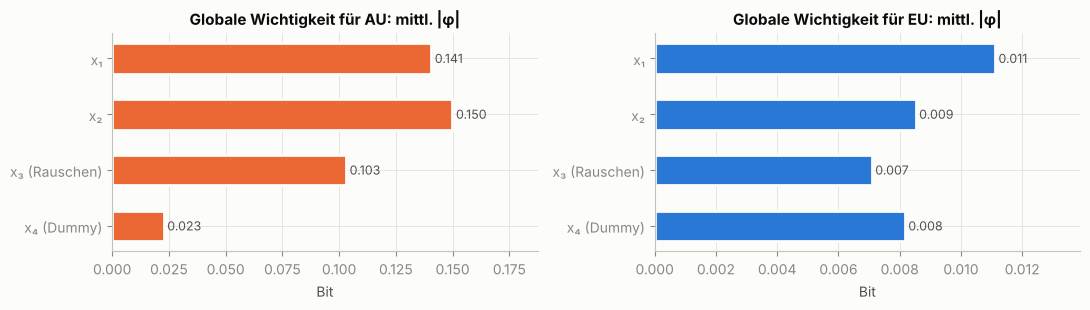

In [21]:
XG4 = X4[np.random.default_rng(SEED + 7).choice(N4, 200, replace=False)]
vG4 = uncertainty_game(ens4, XG4, X4, K=100)
glob = {}
for k in ("AU", "EU"):
    mm = moebius(vG4[k], 4)
    glob[k] = np.abs(np.array([shapley_values(mm[:, p], 4) for p in range(len(XG4))])).mean(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, k in zip(axes, ("AU", "EU")):
    bars = ax.barh(FEAT[::-1], glob[k][::-1], color=C[k], height=0.55, edgecolor=C["surface"], linewidth=2)
    for b, val in zip(bars, glob[k][::-1]):
        ax.text(val, b.get_y() + b.get_height() / 2, f" {val:.3f}", va="center", fontsize=9, color=C["ink2"])
    ax.set_title(f"Globale Wichtigkeit für {k}: mittl. |φ|"); ax.set_xlabel("Bit"); ax.set_xlim(0, glob[k].max() * 1.25)
plt.tight_layout(); plt.show()

**Lesart:** Für AU sind die Mond-Koordinaten am wichtigsten (sie entscheiden, ob man überhaupt weiß, welcher Mond es ist), danach **x₃** als Rausch-Regler. Der **Dummy x₄** liegt klar dahinter. Die globale EU ist auf Trainingspunkten durchweg sehr klein (≈ 0.01 Bit), denn dort hat das Modell Daten gesehen. Auf diesem Niveau ist auch x₄ nicht mehr von den anderen zu unterscheiden; die Werte liegen im Bereich des Rauschens. Ein globaler Blick auf EU wird erst auf Verteilungs-Shift- oder OOD-Daten interessant (Idee T3).

# 12 · Vor- und Nachteile

### Shapley-Interaktionen für Unsicherheit

| Vorteile | Nachteile |
|---|---|
| Unterscheidet „Merkmal ist ungewöhnlich“ von „**Kombination** ist ungewöhnlich“ (Abschnitt 3, 8) | Mehr Werte: $\binom{n}{2}$ Paare zusätzlich, bei 12 Merkmalen 66 Paare, schwer darstellbar |
| Nutzt den Kern von shapiq (k-SII, STII, FSII, Möbius), nicht nur Shapley-Werte | Verschiedene Indizes verteilen höhere Effekte unterschiedlich, die Wahl muss begründet werden |
| Additivität TU = AU + EU gilt auch für Interaktionen, die Erklärungen sind konsistent (Abschnitt 6) | **Imputationsartefakt** wirkt gerade auf Interaktionen (Abschnitt 10), bedingte Imputer sind Pflicht |
| Ground-Truth-Benchmark ist leicht zu bauen und damit gut zu verteidigen (Abschnitt 11) | Effekte dritter Ordnung (Abschnitt 11) werden bei Ordnung 2 umverteilt |
| Direkt in der Kursbeschreibung als Designfrage genannt | Kosten wachsen mit $2^n$ (Tabelle unten) |

### Shapley-Unsicherheitskarten

| Vorteile | Nachteile |
|---|---|
| Ein Bild beantwortet „wo und wodurch“, sehr stark für die Präsentation | Bei > 2 Merkmalen nur als **Schnitt** (2 Merkmale variieren, Rest fest) oder als Karte über eine 2D-Einbettung |
| Deckt die Kurserwartung „Plots für Vorhersage und Unsicherheit“ ab | Viele Erklärpunkte, also Kosten × Gitterpunkte |
| Macht Artefakte sichtbar (D1, D2) und dient damit auch als Debugging-Werkzeug | Allein ist es eher Visualisierung als eigenständiger Forschungsbeitrag |
| Lässt sich als Plot-Modul gut upstream anbieten | Farbskalen, Vorzeichen (D3) und Normierung müssen sorgfältig gewählt werden |

In [22]:
def n_predictions(n, K=100, M=10, points=1):
    return 2 ** n * K * M * points

rows = [{"Merkmale n": n, "Koalitionen 2ⁿ": 2 ** n, "Paare": comb(n, 2),
         "Vorhersagen pro Punkt (K=100, M=10)": f"{n_predictions(n):,}".replace(",", "."),
         "Karte 45×45 Punkte": f"{n_predictions(n, points=45 * 45):,}".replace(",", ".")}
        for n in (2, 4, 8, 12)]
display(pd.DataFrame(rows).set_index("Merkmale n").rename_axis("Kosten (D6)"))

,Koalitionen 2ⁿ,Paare,"Vorhersagen pro Punkt (K=100, M=10)",Karte 45×45 Punkte
Kosten (D6),,,,
2,4,1,4.000,8.100.000
4,16,6,16.000,32.400.000
8,256,28,256.000,518.400.000
12,4096,66,4.096.000,8.294.400.000


**Konsequenz für D6:** Bis ca. 8 Merkmale geht pro Punkt alles exakt. Bei 12 Merkmalen sind einzelne Punkte noch machbar, ganze Karten brauchen aber Approximatoren aus shapiq, weniger Imputationen oder Caching. Karten sind deshalb vor allem für **2D-Schnitte** gedacht.

# 13 · Warum das für unser Projekt sehr relevant sein könnte

### 1. Es deckt alle drei Kurserwartungen ab

| Kurserwartung | Was dieses Notebook schon zeigt | Was im Projekt daraus wird |
|---|---|---|
| **Explainer, der mit jeder probly-Methode funktioniert** | `uncertainty_game` braucht nur „Member-Verteilungen“ und `decompose` | `UncertaintyGame` / `UncertaintyExplainer` auf probly-Repräsentationen (Ensemble, Dropout, …) |
| **Plots für Vorhersage und Unsicherheit nebeneinander** | Balken AU/EU, Interaktionsmatrizen, Karten | Plot-Modul, z. B. `plot_uncertainty_explanation`, `plot_uncertainty_map` |
| **Fallstudie auf tabellarischen Daten** | Benchmark mit 4 Merkmalen | Fallstudie auf California Housing, Heart Disease o. ä. (≤ 12 Merkmale, exakt) |

### 2. Es beantwortet die Designfragen aus der Themenbeschreibung, nicht nur eine

| Designfrage | Beitrag dieses Ansatzes |
|---|---|
| *Wie entfernt man Merkmale, wenn das Modell eine Verteilung liefert?* | Variante A (Abschnitt 6, 9) mit klarer Begründung über Jensen |
| *Wie erklärt man AU und EU getrennt?* | drei Spiele, Additivität geschenkt (Abschnitt 6) |
| *Welche Interaktionen treiben die Unsicherheit?* | **genau das Thema dieses Notebooks** (Abschnitt 3, 7, 8, 11) |

Und unsere eigenen Designfragen: **D1** (Abschnitt 9), **D2** (Abschnitt 10), **D3** (Vorzeichen, Abschnitt 6), **D6** (Kosten, Abschnitt 12) sind schon angerissen.

### 3. Es nutzt **beide** Bibliotheken wesentlich

- **probly:** Repräsentationen (Ensemble, Dropout, …), `decompose` für Klassifikation (Entropie) und Regression (Varianz, D5). Die Additivität TU = AU + EU ist der Grund, warum die Erklärungen konsistent sind.
- **shapiq:** `Game` als Schnittstelle, **Interaktionsindizes** (k-SII, STII, FSII, Möbius), exakte Berechnung und Approximatoren, bedingte Imputer (Gaussian Copula, Generative Conditional) gegen das Artefakt, Netzwerk- und Interaktionsplots.

Ohne Interaktionen würden wir von shapiq nur Shapley-Werte nutzen, und genau die gibt es auch in vielen anderen Bibliotheken.

### 4. Es ist neu und klar abgrenzbar

- **Watson et al. (2023):** Shapley-Werte für prädiktive Unsicherheit, informationstheoretisch. Wir ergänzen **Interaktionen** und die **probly-Breite**.
- **Bley et al. (2024):** Unsicherheit wird von Effekten zweiter Ordnung dominiert, allerdings mit gradienten- und LRP-basierten Erklärungen. Wir arbeiten **modellagnostisch** mit Shapley-Interaktionen **und getrennt nach AU/EU**.
- Unser Abschnitt 11 liefert einen zusätzlichen Befund, der eine eigene Folie wert ist: **Rauschen kann epistemische Unsicherheit verdecken** (Effekt dritter Ordnung).

### 5. Es ist überprüfbar, und das zählt bei „Qualität der Lösung“

Die Checks aus Abschnitt 6 werden direkt zu **pytest-Tests**:

```python
def test_efficiency(game):            # Σ φ_i = v(N) - v(∅)
def test_additivity_tu_au_eu(game):   # φ(TU) = φ(AU) + φ(EU), auch für Interaktionen
def test_dummy_feature(game):         # Modell ignoriert Merkmal j  ->  alle Beiträge mit j = 0
def test_symmetry(game):              # vertauschte identische Merkmale -> gleiche Beiträge
def test_grand_coalition_matches_direct(game):  # v(N) = decompose am Punkt
def test_variant_ordering():          # EU_A <= EU_C (Jensen)
```

Dazu kommt der Ground-Truth-Benchmark (Abschnitt 11) als Integrationstest: „Die größte EU-Paar-Interaktion am Lückenpunkt ist (x₁, x₂).“

### 6. Es ergibt eine starke Präsentation (50 % der Note)

Ein roter Faden mit **einer Frage, einem Bild, einer Antwort**:

1. *Warum ist das Modell hier unsicher?* → TwoMoons-Punkt P3
2. Shapley-Werte sagen „beide Merkmale gleich“ → Abschnitt 8, linke Karten
3. Interaktionen sagen „die **Kombination**“ → Abschnitt 8, rechte Karte
4. Vorsicht: Die Erklärmethode kann Unsicherheit selbst erzeugen → Abschnitt 10
5. Ground Truth bestätigt es, und Rauschen kann EU verdecken → Abschnitt 11
6. Fallstudie auf echten Daten

### 7. Es passt zu den Meilensteinen

| Zeitraum | Konkreter Schritt |
|---|---|
| bis 22.11. | Dieses Notebook im Team durchgehen, Watson et al. gezielt auf D1 lesen |
| 23.11. – 13.12. | `UncertaintyGame` in `src/` als `shapiq.Game`, Tests aus Punkt 5, Ensemble (sklearn, torch) + Dropout |
| 14.12. – 10.01. | Benchmark N1 + Imputer-Vergleich (D2) als eigene Idee; Zwischenpräsentation mit den Karten |
| 11.01. – 24.01. | Fallstudie auf tabellarischem Datensatz, Karten als 2D-Schnitte, Netzwerk-Plots |
| 25.01. – 05.02. | Doku, Beispiel, ggf. Upstream-PR (Plot-Modul oder verteilungsfähiger Imputer) |

### Risiken und wie wir ihnen begegnen

| Risiko | Gegenmaßnahme |
|---|---|
| Kosten bei vielen Merkmalen | Datensatz ≤ 12 Merkmale (Projektplan Abschnitt 10), Caching der Spielauswertungen, shapiq-Approximatoren |
| Artefakt durch marginale Imputation | bedingte Imputer von Anfang an mitvergleichen (N2) |
| Karten bei mehr als 2 Merkmalen | 2D-Schnitte durch interessante Paare, die vorher über die Interaktionsmatrix ausgewählt werden |
| Interpretation für das Publikum | Abschnitt 3 als Einstiegsfolie: gleiche Shapley-Werte, verschiedene Mechanismen |

### Fragen an die Tutoren, die sich hieraus ergeben

1. Ist Variante A (D1) als Standard akzeptabel, mit B/C als Vergleich?
2. Soll der Imputer-Vergleich (D2/N2) Teil der eigenen Idee sein, oder reicht er als Nebenbefund?
3. Wäre ein Plot-Modul für Unsicherheitskarten ein sinnvoller Upstream-PR, und in probly oder in shapiq?

### Fazit

> **Interaktionen** sind der inhaltliche Kern: Sie beantworten die Designfrage „Welche Interaktionen treiben die Unsicherheit?“, nutzen shapiq wesentlich und sind über Ground Truth überprüfbar.
>
> **Shapley-Unsicherheitskarten** sind die Bühne: Sie machen das Ergebnis in einem Bild sichtbar und decken Artefakte auf.
>
> Zusammen bauen sie direkt auf unserem Fundament (Abschnitt 5 des Projektplans) auf, statt es zu ersetzen.

# Anhang A · Brücke zu shapiq und probly

**shapiq-Konvention:** Ein Spiel bekommt eine **boolesche Koalitionsmatrix** (eine Zeile pro Koalition, eine Spalte pro Spieler) und gibt **eine Zahl pro Koalition** zurück. Unsere Funktion lässt sich genau so verpacken. Diese Zelle zeigt die Umrechnung und prüft, dass dieselben Werte herauskommen:

In [23]:
def make_value_function(ensemble, x, background, notion="EU", K=100, imputer=marginal_impute, seed=SEED):
    """Erzeugt value_function(coalitions) -> values im shapiq-Stil (coalitions: bool, Form (n_coal, d))."""
    x = np.atleast_2d(x)
    key = {"total": "TU", "aleatoric": "AU", "epistemic": "EU"}.get(notion, notion)
    def value_function(coalitions):
        values = np.empty(len(coalitions))
        for r, mask in enumerate(np.asarray(coalitions, dtype=bool)):
            Z = imputer(x, mask, background, K, np.random.default_rng(seed))
            P = ensemble.predict_members(Z.reshape(-1, x.shape[1])).reshape(len(ensemble.members), K, -1)
            tu, au, eu = decompose(P.mean(axis=1))
            values[r] = {"TU": tu, "AU": au, "EU": eu}[key]
        return values
    return value_function

vf = make_value_function(ens, XP[2], BACKGROUND, notion="epistemic")
coalitions = np.array([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=bool)
print("value_function:", vf(coalitions).round(4))
print("uncertainty_game:", vP["EU"][:, 2].round(4), "(Bitmasken-Reihenfolge ∅, {x₁}, {x₂}, {x₁,x₂})")

value_function: [0.0002 0.0178 0.0043 0.1462]
uncertainty_game: [0.0002 0.0178 0.0043 0.1462] (Bitmasken-Reihenfolge ∅, {x₁}, {x₂}, {x₁,x₂})


### Skizze für `src/` (noch nicht ausgeführt, API gegen die aktuelle shapiq- und probly-Doku prüfen)

```python
import shapiq

class UncertaintyGame(shapiq.Game):
    # Unsicherheit einer probly-Repräsentation als kooperatives Spiel

    def __init__(self, representer, x, background, notion="epistemic", n_imputations=100, imputer="marginal"):
        self._vf = make_value_function(...)          # wie oben, aber auf probly-Repräsentationen
        super().__init__(n_players=x.shape[-1], normalize=False)

    def value_function(self, coalitions):
        return self._vf(coalitions)
```

Danach liefern die shapiq-Werkzeuge (exakte Berechnung oder Approximatoren für SV, k-SII, STII, FSII, Möbius) die `InteractionValues`, und shapiqs Plots (force, waterfall, network, si_graph, upset) funktionieren direkt.

**Offene Punkte für die Umsetzung:**
- Wie liefern probly-Repräsentationen die Member-Verteilungen (`representer(model).represent(x)`), und wie heißt die passende Zerlegung (`SecondOrderEntropyDecomposition`, `SecondOrderVarianceDecomposition`)?
- **Caching:** TU, AU und EU entstehen aus derselben Spielauswertung. Ein `UncertaintyExplainer` sollte alle drei in **einem** Durchlauf berechnen.
- Ort im Code (D4): `probly.integrations.shapiq` oder eigenes Paket.

## Quellen

- Watson, O'Hara, Tax, Mudd, Guy (2023): *Explaining Predictive Uncertainty with Information Theoretic Shapley Values*, NeurIPS. https://arxiv.org/abs/2306.05724
- Bley et al. (2024): *Explaining Predictive Uncertainty by Exposing Second-Order Effects*. https://arxiv.org/abs/2401.17441
- Grabisch & Roubens (1999): *An axiomatic approach to the concept of interaction among players in cooperative games*. International Journal of Game Theory.
- Sundararajan, Dhamdhere, Agarwal (2020): *The Shapley Taylor Interaction Index*. ICML. https://arxiv.org/abs/1902.05622
- Bordt & von Luxburg (2023): *From Shapley Values to Generalized Additive Models and back*. AISTATS. https://arxiv.org/abs/2209.04012
- Tsai, Yeh, Ravikumar (2023): *Faith-Shap: The Faithful Shapley Interaction Index*. JMLR. https://arxiv.org/abs/2203.00870
- shapiq: https://github.com/mmschlk/shapiq · Doku: https://shapiq.readthedocs.io/
- probly: https://github.com/pwhofman/probly